# UTS Graf Sains Data — RetailRocket & Neo4j
Notebook ini mencakup wrangling/EDA, filter dua periode, impor graf Neo4j, komposisi subgraph, VSM, proyeksi user/item, similarity, KNN recommendation, Hit@5, dan NDCG@5.

**Pilihan periode awal (konfirmasi agar tidak sama dengan mahasiswa lain):**
- P1/training: 3 Mei 2015–30 Juni 2015
- P2/testing: 1 Juli 2015–18 September 2015

Rentang tanggal akhir inklusif. Dataset RetailRocket memakai timestamp Unix milidetik.

## 0. Instalasi dan import
Jalankan `%pip install -r requirements.txt` jika paket belum terpasang.

In [1]:
%pip install pandas numpy matplotlib networkx scikit-learn tqdm neo4j

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\nachla\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [17]:
import os, zipfile, random, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from neo4j import GraphDatabase
from IPython.display import display
from scipy.sparse import csr_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

## 1. Unduh dan baca dataset
Jika unduhan otomatis gagal, unduh ZIP RetailRocket dari tautan Kaggle pada soal dan simpan sebagai `data/ecommerce-dataset.zip`.

In [3]:
zip_path = DATA_DIR / "ecommerce-dataset.zip"
events_path = DATA_DIR / "events.csv"
if not events_path.exists():
    if not zip_path.exists():
        url = "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"
        urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        candidates = [x for x in zf.namelist() if x.lower().endswith("events.csv")]
        if not candidates:
            raise FileNotFoundError("events.csv tidak ditemukan di ZIP.")
        with zf.open(candidates[0]) as src, open(events_path, "wb") as dst:
            dst.write(src.read())
df_raw = pd.read_csv(events_path)
print(df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes)

(2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


timestamp          int64
visitorid          int64
event             object
itemid             int64
transactionid    float64
dtype: object

## 2. Wrangling dan EDA

Rentang aktual: 2015-05-03 03:00:04.384000 s.d. 2015-09-18 02:59:47.788000
Jumlah baris: 2756101 | user unik: 1407580 | item unik: 235061


,jumlah
event,
view,2664312
addtocart,69332
transaction,22457


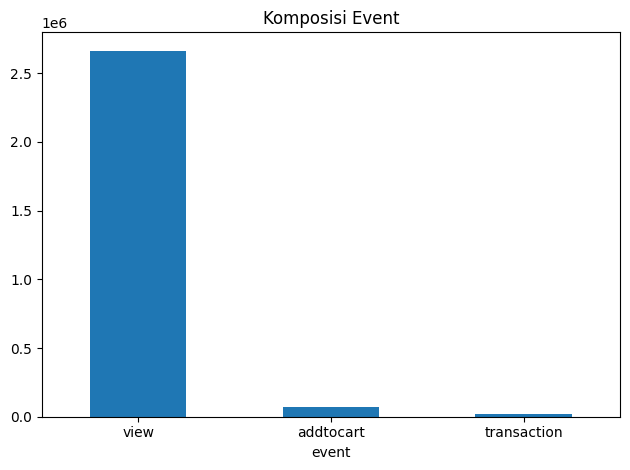

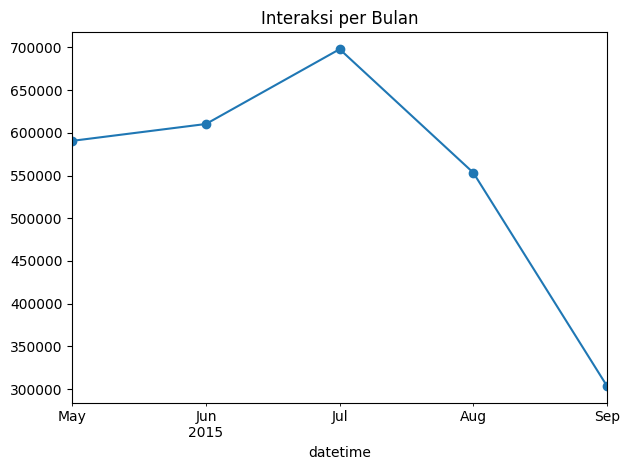

In [37]:
required = {"timestamp", "visitorid", "event", "itemid", "transactionid"}
missing = required - set(df_raw.columns)
if missing:
    raise ValueError(f"Kolom hilang: {missing}")
df = df_raw.copy()
for c in ["timestamp", "visitorid", "itemid"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=["timestamp", "visitorid", "itemid", "event"]).copy()
df["timestamp"] = df["timestamp"].astype("int64")
df["visitorid"] = df["visitorid"].astype("int64")
df["itemid"] = df["itemid"].astype("int64")
df["event"] = df["event"].astype(str).str.lower().str.strip()
df["transactionid"] = df["transactionid"].fillna("").astype(str)
df["datetime"] = (pd.to_datetime(df["timestamp"], unit="ms", utc=True).dt.tz_convert(None))
print("Rentang aktual:", df["datetime"].min(), "s.d.", df["datetime"].max())
print("Jumlah baris:", len(df), "| user unik:", df["visitorid"].nunique(), "| item unik:", df["itemid"].nunique())
display(df["event"].value_counts().rename_axis("event").to_frame("jumlah"))
df["event"].value_counts().plot(kind="bar", rot=0, title="Komposisi Event")
plt.tight_layout()
plt.show()
df.groupby(df["datetime"].dt.to_period("M")).size().plot(marker="o", title="Interaksi per Bulan")
plt.tight_layout()
plt.show()

## 3. Filter periode P1 dan P2; simpan CSV

In [38]:
P1_START = pd.Timestamp("2015-05-10 00:00:00")
P1_END   = pd.Timestamp("2015-06-10 00:00:00")  
P2_START = pd.Timestamp("2015-07-20 00:00:00")
P2_END   = pd.Timestamp("2015-08-20 00:00:00")  
p1 = df.loc[(df["datetime"] >= P1_START) & (df["datetime"] < P1_END)].copy()
p2 = df.loc[(df["datetime"] >= P2_START) & (df["datetime"] < P2_END)].copy()
cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
p1[cols].to_csv(DATA_DIR / "events_P1_training.csv", index=False)
p2[cols].to_csv(DATA_DIR / "events_P2_testing.csv", index=False)
ringkasan = pd.DataFrame({
    "periode": ["P1 training", "P2 testing"], 
    "mulai": [P1_START, P2_START], 
    "akhir": [P1_END, P2_END], 
    "interaksi": [len(p1), len(p2)], 
    "user_unik": [p1["visitorid"].nunique(), p2["visitorid"].nunique()], 
    "item_unik": [p1["itemid"].nunique(), p2["itemid"].nunique()]})
display(ringkasan)
print("File P1 tersimpan:", DATA_DIR / "events_P1_training.csv")
print("File P2 tersimpan:", DATA_DIR / "events_P2_testing.csv")

,periode,mulai,akhir,interaksi,user_unik,item_unik
0,P1 training,2015-05-10,2015-06-10,646405,336652,120640
1,P2 testing,2015-07-20,2015-08-20,630793,347299,120114


File P1 tersimpan: data\events_P1_training.csv
File P2 tersimpan: data\events_P2_testing.csv


## 4. Koneksi Neo4j
Pastikan Neo4j aktif. Ubah kredensial di bawah atau atur environment variables. Jangan commit password ke GitHub.

In [39]:
NEO4J_URI = os.getenv("NEO4J_URI", "bolt://localhost:7687")
NEO4J_USER = os.getenv("NEO4J_USER", "neo4j")
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD", "nachla18")
NEO4J_DATABASE = os.getenv("NEO4J_DATABASE", "neo4j")
driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
driver.verify_connectivity()
def query(q, params=None):
    with driver.session(database=NEO4J_DATABASE) as s:
        return list(s.run(q, params or {}))
print("Neo4j tersambung.")

Neo4j tersambung.


## 5. Impor interaksi P1 ke graf
Struktur graf: `(Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(Item)`. **Peringatan:** penghapusan di bawah membersihkan semua node dalam database yang dipilih. Gunakan database khusus tugas.

In [41]:
assert "p1" in globals(), "Jalankan CELL 3 terlebih dahulu."
assert not p1.empty, "Dataset P1 kosong."
assert "driver" in globals(), "Koneksi Neo4j belum dibuat."
assert "NEO4J_DATABASE" in globals(), "Database Neo4j belum ditentukan."
print("=== VALIDASI DATA P1 ===")
print("Periode mulai   :", p1["datetime"].min())
print("Periode akhir   :", p1["datetime"].max())
print("Jumlah interaksi:", len(p1))
print("User unik       :", p1["visitorid"].nunique())
print("Item unik       :", p1["itemid"].nunique())
def query(cypher, parameters=None):
    with driver.session(database=NEO4J_DATABASE) as session:
        result = session.run(cypher, parameters or {})
        return [record.data() for record in result]
query("""
CREATE CONSTRAINT visitor_id IF NOT EXISTS
FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE
""")
query("""
CREATE CONSTRAINT item_id IF NOT EXISTS
FOR (i:Item) REQUIRE i.itemId IS UNIQUE
""")
print("\n=== MENGHAPUS GRAF LAMA ===")
while True:
    deleted = query("""
        MATCH (n)
        WITH n LIMIT 1000
        DETACH DELETE n
        RETURN count(*) AS deleted
    """)
    jumlah = deleted[0]["deleted"] if deleted else 0
    print("Node dihapus:", jumlah)
    if jumlah == 0:
        break
print("Graf lama berhasil dibersihkan.")
def import_batch(tx, rows):
    cypher = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        RETURN 1 AS x

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        RETURN 1 AS x

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
        RETURN 1 AS x
    }

    RETURN count(*) AS imported
    """
    tx.run(cypher, batch=rows).consume()
cols = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid"
]
records = p1[cols].to_dict("records")
batch_size = 5000
print("\n=== PROSES IMPOR P1 ===")
print("Total record:", len(records))
with driver.session(database=NEO4J_DATABASE) as session:
    for start in range(0, len(records), batch_size):
        batch = records[start:start + batch_size]
        session.execute_write(import_batch, batch)

        print(
            f"Diimpor: {min(start + batch_size, len(records))}"
            f" / {len(records)}"
        )
print("\nImpor P1 selesai.")
hasil = query("""
MATCH (v:Visitor)
WITH count(v) AS total_visitor
MATCH (i:Item)
WITH total_visitor, count(i) AS total_item
MATCH ()-[r]->()
RETURN
    total_visitor AS visitor,
    total_item AS item,
    count(r) AS relasi
""")
display(pd.DataFrame(hasil))

=== VALIDASI DATA P1 ===
Periode mulai   : 2015-05-10 00:00:07.942000
Periode akhir   : 2015-06-09 23:59:59.063000
Jumlah interaksi: 646405
User unik       : 336652
Item unik       : 120640

=== MENGHAPUS GRAF LAMA ===
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
Node dihapus: 1000
No

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=5, offset=140>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 140, 'line': 8, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n        RETURN 1 AS x\n\n        UNION ALL\n

Diimpor: 5000 / 646405


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=5, offset=140>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 140, 'line': 8, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n        RETURN 1 AS x\n\n        UNION ALL\n

Diimpor: 10000 / 646405


...

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=5, offset=140>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 140, 'line': 8, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n        RETURN 1 AS x\n\n        UNION ALL\n

Diimpor: 645000 / 646405


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=5, offset=140>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 140, 'line': 8, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n        RETURN 1 AS x\n\n        UNION ALL\n

Diimpor: 646405 / 646405

Impor P1 selesai.


,visitor,item,relasi
0,336652,120640,646405


## 6. Komposisi subgraph: jumlah node dan relasi

In [42]:
node_q = "MATCH (n) WITH labels(n) AS l RETURN head(l) AS jenis_simpul, count(*) AS jumlah ORDER BY jenis_simpul"
rel_q = "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah ORDER BY jenis_relasi"
print("=== JUMLAH NODE ===")
display(pd.DataFrame(query(node_q)))
print("=== JUMLAH RELASI ===")
display(pd.DataFrame(query(rel_q)))

=== JUMLAH NODE ===


,jenis_simpul,jumlah
0,Item,120640
1,Visitor,336652


=== JUMLAH RELASI ===


,jenis_relasi,jumlah
0,ADDED_TO_CART,15311
1,BOUGHT,4983
2,VIEWED,626111


## 7. VSM dan proyeksi User–User serta Item–Item
Matriks biner menunjukkan apakah user berinteraksi dengan item. Visualisasi dibatasi pada entitas teraktif agar grafik tetap terbaca.

Shape VSM User x Item: (336652, 120640)
Jumlah interaksi unik: 502666
Contoh 5 user pertama, 8 item pertama:


,355908,248676,318965,253185,367447,22556,443030,439202
257597,1,0,0,0,0,0,0,0
992329,0,1,0,0,0,0,0,0
111016,0,0,1,0,0,0,0,0
483717,0,0,0,1,0,0,0,0
951259,0,0,0,0,1,0,0,0


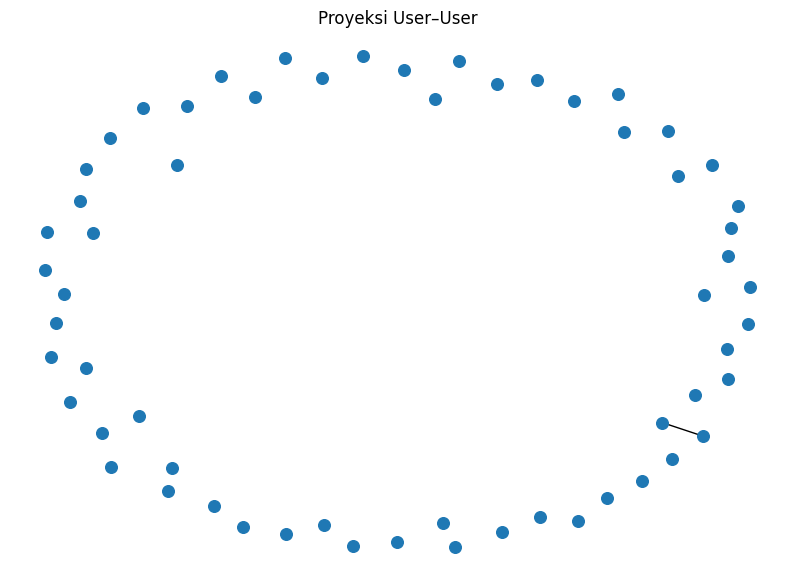

Node: 60 | Edge: 1 | Matrix: (60, 120640)


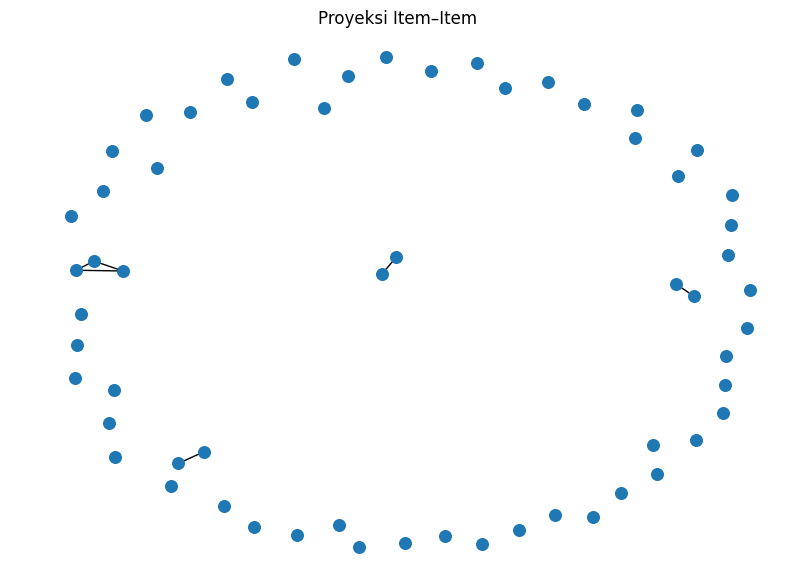

Node: 60 | Edge: 6 | Matrix: (60, 336652)


In [55]:
interaksi = p1[["visitorid", "itemid"]].drop_duplicates()
user_codes, user_ids = pd.factorize(interaksi["visitorid"])
item_codes, item_ids = pd.factorize(interaksi["itemid"])
ui = csr_matrix((np.ones(len(interaksi), dtype=np.uint8),(user_codes, item_codes)),shape=(len(user_ids), len(item_ids)),dtype=np.uint8)
print("Shape VSM User x Item:", ui.shape)
print("Jumlah interaksi unik:", ui.nnz)
print("Contoh 5 user pertama, 8 item pertama:")
display(pd.DataFrame(ui[:5, :8].toarray(),index=user_ids[:5],columns=item_ids[:8]))
def plot_projection(matrix, entity_ids, title, max_nodes=60, threshold=0.15):
    activity = np.asarray(matrix.sum(axis=1)).ravel()
    selected = np.argsort(activity)[::-1][:max_nodes]
    sub = matrix[selected]
    ids = entity_ids[selected]
    sim = cosine_similarity(sub)
    G = nx.Graph()
    G.add_nodes_from(ids.tolist())

    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            if sim[i, j] >= threshold:
                G.add_edge(ids[i], ids[j], weight=float(sim[i, j]))

    plt.figure(figsize=(10, 7))
    pos = nx.spring_layout(G, seed=SEED)
    nx.draw_networkx(G, pos, node_size=70, font_size=6, with_labels=False)
    plt.title(title)
    plt.axis("off")
    plt.show()
    print("Node:", G.number_of_nodes(), "| Edge:", G.number_of_edges(), "| Matrix:", sub.shape)
    return G
G_user = plot_projection(ui, np.asarray(user_ids), "Proyeksi User–User")
G_item = plot_projection(ui.T.tocsr(), np.asarray(item_ids), "Proyeksi Item–Item")

### 6. Perbandingan Proyeksi User dan Item

Berdasarkan hasil VSM, matriks interaksi User-Item memiliki dimensi sebesar **(336.652, 120.640)**, yang merepresentasikan 336.652 pengguna dan 120.640 item. Jumlah interaksi unik yang digunakan dalam pembentukan matriks adalah 502.666.

Pada visualisasi proyeksi User-User, diperoleh 60 simpul dan 1 sisi (*edge*). Sementara itu, proyeksi Item–Item menghasilkan 60 simpul dan 6 sisi. Hasil tersebut menunjukkan bahwa pada sampel visualisasi yang digunakan, hubungan kemiripan antaritem lebih banyak terbentuk dibandingkan hubungan kemiripan antar pengguna.

Dari sisi interpretasi, proyeksi User–User dapat digunakan untuk menemukan pengguna yang memiliki pola interaksi serupa, sedangkan proyeksi Item–Item dapat digunakan untuk menemukan item yang memiliki pola interaksi serupa berdasarkan pengguna yang berinteraksi dengannya.

Dengan demikian, proyeksi Item–Item menunjukkan lebih banyak hubungan pada visualisasi yang dihasilkan. Namun, jumlah sisi tersebut belum cukup untuk menyimpulkan bahwa Item–Item lebih efisien secara keseluruhan, karena visualisasi hanya menggunakan 60 entitas dan belum menggambarkan keseluruhan graf. Untuk kebutuhan rekomendasi menggunakan K-Nearest Neighbors (KNN) berbasis kemiripan pengguna, proyeksi User–User tetap relevan secara konseptual. Penentuan proyeksi yang lebih efektif perlu mempertimbangkan kebutuhan analisis serta biaya komputasinya.

## 8. Hitung dan simpan similarity ke Neo4j
Karena similarity penuh mahal untuk data besar, batasi jumlah entitas. Jika ukuran matriks melewati batas, kurangi entitas atau gunakan implementasi sparse/top-k.

In [45]:
SIM_THRESHOLD = 0.10
TOP_K = 10
MAX_ENTITIES = 2000

def topk_edges(mat, ids, threshold=SIM_THRESHOLD, top_k=TOP_K):
    sim = cosine_similarity(mat)
    edges = {}

    for i, a in enumerate(ids):
        order = np.argsort(sim[i])[::-1]
        kept = 0

        for j in order:
            if i == j:
                continue

            score = float(sim[i, j])
            if score < threshold:
                break

            pair = tuple(sorted((int(a), int(ids[j]))))
            edges[pair] = max(edges.get(pair, 0.0), score)

            kept += 1
            if kept >= top_k:
                break

    return pd.DataFrame([(a, b, s) for (a, b), s in edges.items()], columns=["a", "b", "similarity"])

def select_active(matrix, ids, max_entities=MAX_ENTITIES):
    # Pilih entitas dengan jumlah interaksi terbanyak
    activity = np.asarray(matrix.sum(axis=1)).ravel()
    selected = np.argsort(activity)[::-1][:max_entities]
    return matrix[selected], np.asarray(ids)[selected]

user_edges = pd.DataFrame(columns=["a", "b", "similarity"])
item_edges = pd.DataFrame(columns=["a", "b", "similarity"])

user_mat, selected_users = select_active(ui, user_ids.to_numpy())
user_edges = topk_edges(user_mat, selected_users)

item_mat, selected_items = select_active(ui.T.tocsr(), item_ids.to_numpy())
item_edges = topk_edges(item_mat, selected_items)

print("User edges:", len(user_edges), "| Item edges:", len(item_edges))

def save_edges(label, idprop, edges):
    if edges.empty:
        return

    q = ("UNWIND $rows AS row " f"MATCH (a:{label} {{{idprop}: row.a}}) " f"MATCH (b:{label} {{{idprop}: row.b}}) " "MERGE (a)-[r:SIMILAR_TO]-(b) " "SET r.similarity = row.similarity")

    with driver.session(database=NEO4J_DATABASE) as s:
        rows = edges.to_dict("records")
        for start in range(0, len(rows), 5000):
            s.run(q, rows=rows[start:start + 5000]).consume()

save_edges("Visitor", "visitorId", user_edges)
save_edges("Item", "itemId", item_edges)

User edges: 4675 | Item edges: 1462


## 7. Perhitungan Similarity pada Graf Terproyeksi

Perhitungan similarity dilakukan menggunakan Python dengan metode *cosine similarity* untuk mengukur kemiripan pola interaksi antarentitas. Perhitungan dilakukan pada proyeksi User–User dan Item–Item berdasarkan representasi vektor interaksi pada VSM.

Hasil perhitungan menghasilkan **4.675 relasi similarity pada proyeksi User–User** dan **1.462 relasi similarity pada proyeksi Item–Item**. Setiap relasi menyimpan nilai kemiripan yang digunakan untuk menunjukkan tingkat kesamaan pola interaksi antara dua entitas.

Selanjutnya, hasil perhitungan similarity disimpan ke dalam graf Neo4j menggunakan relasi `SIMILAR_TO`. Nilai kemiripan disimpan pada properti `similarity`, sehingga dapat ditelusuri dan dianalisis kembali menggunakan query Cypher.

### 7(a). Query Cypher untuk Mendapatkan Lima Similarity Tertinggi

Query berikut digunakan untuk mengambil lima relasi `SIMILAR_TO` dengan nilai similarity tertinggi dari graf Neo4j.

In [56]:
top_q = "MATCH (a)-[r:SIMILAR_TO]-(b) WHERE elementId(a) < elementId(b) RETURN labels(a)[0] AS jenis, coalesce(a.visitorId, a.itemId) AS entitas_a, coalesce(b.visitorId, b.itemId) AS entitas_b, r.similarity AS similarity ORDER BY similarity DESC LIMIT 5"
hasil_top5 = query(top_q)
display(pd.DataFrame(hasil_top5))

,jenis,entitas_a,entitas_b,similarity
0,Item,354759,452896,0.883883
1,Visitor,699471,641040,0.870727
2,Visitor,1029863,1312606,0.769231
3,Visitor,1315253,649511,0.735767
4,Visitor,1029863,580290,0.652714


Hasil query menunjukkan lima pasangan entitas dengan nilai similarity tertinggi pada graf. Pasangan dengan nilai similarity tertinggi adalah dua item, yaitu item 354759 dan item 452896, dengan nilai sebesar **0,883883**. Nilai tersebut menunjukkan kemiripan pola interaksi yang tinggi berdasarkan representasi vektor yang digunakan.

Empat pasangan berikutnya merupakan pasangan pengguna (*Visitor*). Pasangan Visitor 699471 dan Visitor 641040 memiliki nilai similarity sebesar 0,870727, diikuti Visitor 1029863 dan Visitor 1312606 sebesar 0,769231. Selanjutnya, pasangan Visitor 1315253 dan Visitor 649511 memiliki nilai 0,735767, sedangkan pasangan Visitor 1029863 dan Visitor 580290 memiliki nilai 0,652714.

Hasil tersebut memperlihatkan bahwa relasi similarity dapat terbentuk pada proyeksi User–User maupun Item–Item. Semakin tinggi nilai cosine similarity, semakin mirip pola interaksi kedua entitas berdasarkan vektor yang digunakan.

### 7(b). Menyimpan dan Memeriksa Nilai Similarity pada Graf

Nilai similarity yang dihitung menggunakan Python disimpan pada properti similarity dalam relasi SIMILAR_TO. Penyimpanan ini memungkinkan nilai hasil perhitungan diperiksa kembali melalui query Cypher. Dengan demikian, hasil perhitungan similarity tidak hanya tersedia dalam bentuk tabel Python, tetapi juga tersimpan sebagai bagian dari graf Neo4j.

In [57]:
query("MATCH (a)-[r:SIMILAR_TO]-(b) WHERE elementId(a) < elementId(b) RETURN labels(a)[0] AS jenis, coalesce(a.visitorId, a.itemId) AS entitas_a, coalesce(b.visitorId, b.itemId) AS entitas_b, r.similarity AS similarity ORDER BY similarity DESC LIMIT 5")

[{'jenis': 'Item',
  'entitas_a': 354759,
  'entitas_b': 452896,
  'similarity': 0.883883476483184},
 {'jenis': 'Visitor',
  'entitas_a': 699471,
  'entitas_b': 641040,
  'similarity': 0.8707265026259212},
 {'jenis': 'Visitor',
  'entitas_a': 1029863,
  'entitas_b': 1312606,
  'similarity': 0.7692307692307692},
 {'jenis': 'Visitor',
  'entitas_a': 1315253,
  'entitas_b': 649511,
  'similarity': 0.7357672073819591},
 {'jenis': 'Visitor',
  'entitas_a': 1029863,
  'entitas_b': 580290,
  'similarity': 0.6527139518645056}]

In [58]:
hasil_b = query("MATCH (a)-[r:SIMILAR_TO]-(b) WHERE elementId(a) < elementId(b) RETURN labels(a)[0] AS jenis, coalesce(a.visitorId, a.itemId) AS entitas_a, coalesce(b.visitorId, b.itemId) AS entitas_b, r.similarity AS similarity ORDER BY similarity DESC LIMIT 5")
display(pd.DataFrame(hasil_b))

,jenis,entitas_a,entitas_b,similarity
0,Item,354759,452896,0.883883
1,Visitor,699471,641040,0.870727
2,Visitor,1029863,1312606,0.769231
3,Visitor,1315253,649511,0.735767
4,Visitor,1029863,580290,0.652714


### Interpretasi Hasil Pemeriksaan Similarity pada Neo4j

Berdasarkan hasil query pemeriksaan pada Neo4j, diperoleh lima relasi `SIMILAR_TO` dengan nilai similarity tertinggi yang sama dengan hasil query sebelumnya. Hal ini menunjukkan bahwa nilai similarity hasil perhitungan Python telah tersimpan dan dapat diakses kembali melalui graf Neo4j.

Relasi dengan nilai similarity tertinggi menghubungkan item 354759 dan item 452896 dengan nilai 0,883883. Selanjutnya, pasangan Visitor 699471 dan Visitor 641040 memiliki nilai 0,870727. Tiga pasangan berikutnya memiliki nilai masing-masing 0,769231, 0,735767, dan 0,652714.

Dengan demikian, penyimpanan similarity pada graf Neo4j berhasil diperiksa melalui query Cypher. Hasil ini memenuhi kebutuhan untuk menampilkan lima relasi similarity tertinggi dan membuktikan bahwa nilai similarity dapat ditelusuri kembali dari graf.

## 9. Query Cypher similarity tertinggi dan graf sebelum/sesudah

In [46]:
top_q = "MATCH (a)-[r:SIMILAR_TO]-(b) WHERE elementId(a) < elementId(b) RETURN labels(a)[0] AS jenis, coalesce(a.visitorId, a.itemId) AS entitas_a, coalesce(b.visitorId, b.itemId) AS entitas_b, r.similarity AS similarity ORDER BY similarity DESC LIMIT 5"
print("=== TOP 5 SIMILARITY TERTINGGI ===")
display(pd.DataFrame(query(top_q)))

=== TOP 5 SIMILARITY TERTINGGI ===


,jenis,entitas_a,entitas_b,similarity
0,Item,354759,452896,0.883883
1,Visitor,699471,641040,0.870727
2,Visitor,1029863,1312606,0.769231
3,Visitor,1315253,649511,0.735767
4,Visitor,1029863,580290,0.652714


### 8. Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

Pada tahap sebelum perhitungan similarity, graf Neo4j merepresentasikan interaksi antara pengguna (*Visitor*) dan item melalui relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Graf ini menggambarkan aktivitas interaksi pengguna terhadap item.

Setelah perhitungan similarity menggunakan Python, hasil kemiripan disimpan ke Neo4j dalam bentuk relasi `SIMILAR_TO` dengan properti `similarity`. Relasi tersebut menghubungkan dua pengguna yang memiliki pola interaksi serupa atau dua item yang memiliki pola interaksi serupa.

Perbandingan kedua kondisi dilakukan melalui query Cypher untuk menghitung jenis dan jumlah relasi, serta menampilkan subgraf sebelum dan sesudah penambahan relasi similarity. Dengan demikian, perubahan struktur graf dapat diamati melalui bertambahnya relasi kemiripan, tanpa menghilangkan relasi interaksi yang sudah ada.

In [59]:
q_sebelum = "MATCH ()-[r]->() WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT'] RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jenis_relasi"
q_sesudah = "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jenis_relasi"
print("KONDISI SEBELUM SIMILARITY")
display(pd.DataFrame(query(q_sebelum)))
print("KONDISI SESUDAH SIMILARITY")
display(pd.DataFrame(query(q_sesudah)))

KONDISI SEBELUM SIMILARITY


,jenis_relasi,jumlah
0,ADDED_TO_CART,15311
1,BOUGHT,4983
2,VIEWED,626111


KONDISI SESUDAH SIMILARITY


,jenis_relasi,jumlah
0,ADDED_TO_CART,15311
1,BOUGHT,4983
2,SIMILAR_TO,6137
3,VIEWED,626111


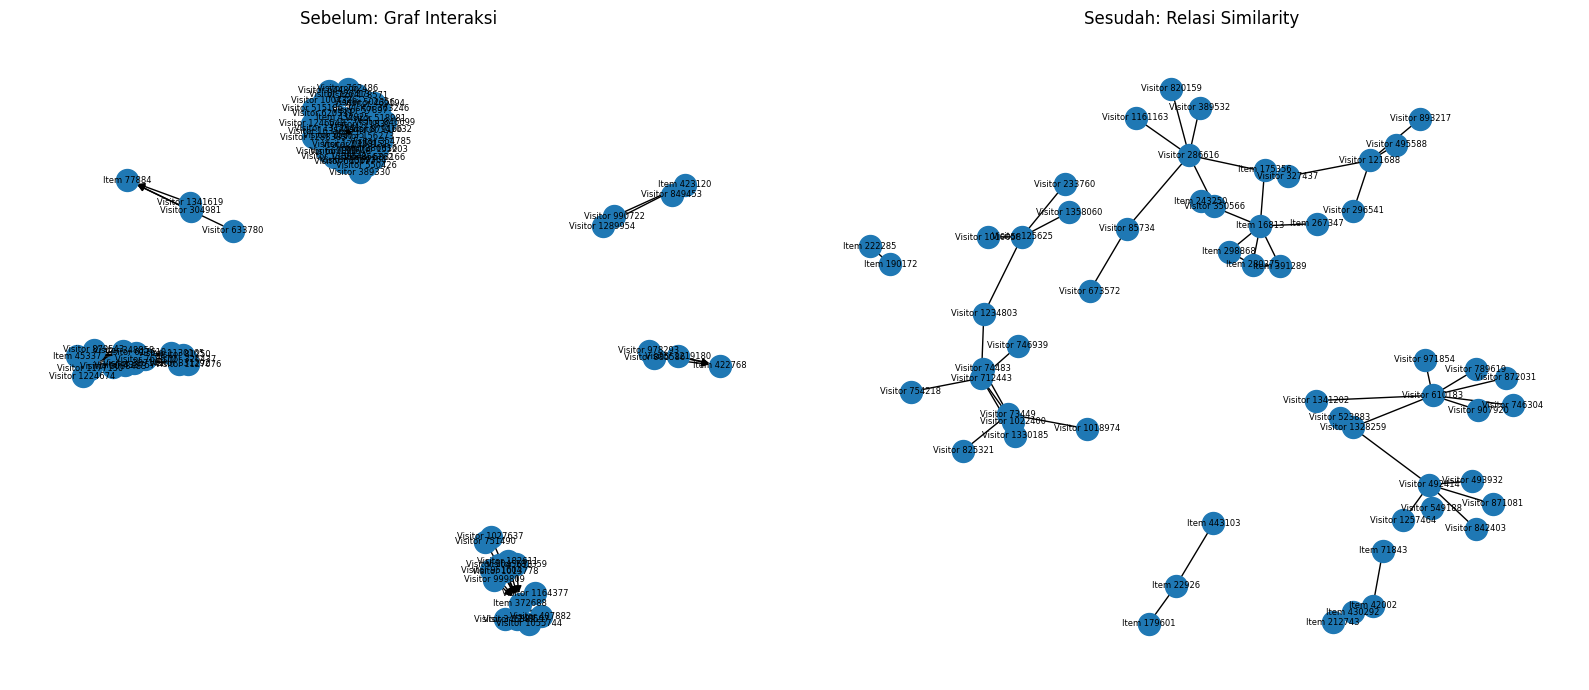

In [60]:
q_graf_sebelum = "MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item) WITH v, r, i LIMIT 100 RETURN v.visitorId AS sumber, type(r) AS relasi, i.itemId AS tujuan"
q_graf_sesudah = "MATCH (a)-[r:SIMILAR_TO]-(b) WITH a, r, b LIMIT 100 RETURN coalesce(a.visitorId, a.itemId) AS sumber, labels(a)[0] AS jenis_sumber, coalesce(b.visitorId, b.itemId) AS tujuan, labels(b)[0] AS jenis_tujuan, r.similarity AS similarity"
sebelum_df = pd.DataFrame(query(q_graf_sebelum))
sesudah_df = pd.DataFrame(query(q_graf_sesudah))
G_sebelum = nx.DiGraph()
for _, row in sebelum_df.iterrows(): G_sebelum.add_edge(f"Visitor {row['sumber']}", f"Item {row['tujuan']}", label=row["relasi"])
G_sesudah = nx.Graph()
for _, row in sesudah_df.iterrows(): G_sesudah.add_edge(f"{row['jenis_sumber']} {row['sumber']}", f"{row['jenis_tujuan']} {row['tujuan']}", weight=row["similarity"])
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
pos1 = nx.spring_layout(G_sebelum, seed=42)
nx.draw_networkx(G_sebelum, pos1, ax=axes[0], node_size=250, font_size=6, arrows=True)
axes[0].set_title("Sebelum: Graf Interaksi")
axes[0].axis("off")
pos2 = nx.spring_layout(G_sesudah, seed=42)
nx.draw_networkx(G_sesudah, pos2, ax=axes[1], node_size=250, font_size=6)
axes[1].set_title("Sesudah: Relasi Similarity")
axes[1].axis("off")
plt.tight_layout()
plt.show()

**Graf sebelum similarity** — jalankan di Neo4j Browser:
```cypher
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v, r, i
LIMIT 100
```

**Graf sesudah similarity:**
```cypher
MATCH (a)-[r:SIMILAR_TO]-(b)
RETURN a, r, b
ORDER BY r.similarity DESC
LIMIT 100
```

**Lima similarity tertinggi:**
```cypher
MATCH (a)-[r:SIMILAR_TO]-(b)
WHERE elementId(a) < elementId(b)
RETURN labels(a)[0] AS jenis,
       coalesce(a.visitorId, a.itemId) AS entitas_a,
       coalesce(b.visitorId, b.itemId) AS entitas_b,
       r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
```

## 10. Analytics: pilih user acak yang reproducible

In [65]:
eligible_better = [
    uid for uid in eligible
    if len(p1_items.get(uid, set())) >= 2
]
print("Jumlah kandidat target:", len(eligible_better))
if eligible_better:
    target_user = random.Random(SEED).choice(eligible_better)
    print("Target user baru:", target_user)
    print("Item P1:", len(p1_items.get(target_user, set())))
    print("Item P2:", len(p2_items.get(target_user, set())))
else:
    target_user = None
    print("Tidak ada target yang memenuhi syarat.")

Jumlah kandidat target: 12729
Target user baru: 1157287
Item P1: 2
Item P2: 2


### 1a. Pemilihan User Secara Acak dan Skrip Python KNN

Pemilihan user dilakukan secara acak dari daftar kandidat user yang tersedia pada User-Item Vector Space Model (VSM). Untuk memastikan proses pemilihan dapat direproduksi, digunakan nilai *random seed* sebesar 42. Dengan seed dan daftar kandidat yang sama serta urutan kandidat yang konsisten, pemilihan user akan menghasilkan target yang sama.

Algoritma *K-Nearest Neighbors* (KNN) digunakan untuk mencari lima user tetangga terdekat (\(k=5\)) berdasarkan nilai *cosine similarity* dari interaksi user terhadap item pada periode training (P1). Item yang telah diinteraksikan oleh target user dikeluarkan dari kandidat rekomendasi. Selanjutnya, skor rekomendasi dihitung dengan menjumlahkan nilai *cosine similarity* dari tetangga yang berinteraksi dengan setiap item kandidat. Item diurutkan berdasarkan skor tertinggi untuk menghasilkan rekomendasi.

## 11. KNN dengan k=5 dan 3 rekomendasi
Tetangga dicari berdasarkan cosine distance dari vektor user-item P1. Item yang sudah disentuh target di P1 tidak direkomendasikan kembali.

In [64]:
K = 5
MAX_KNN_USERS = 20000
if not eligible_better:
    raise ValueError("Tidak ada kandidat target. Periksa CELL 10.")
user_ids_array = np.asarray(user_ids)
available_users = set(user_ids_array.tolist())
valid_targets = [uid for uid in eligible_better if uid in available_users]
if not valid_targets:
    raise ValueError("Tidak ada target yang tersedia dalam VSM.")
target_user = random.Random(SEED).choice(valid_targets)
pos = np.where(user_ids_array == target_user)[0][0]
print("Target user:", target_user)
print("Posisi dalam VSM:", pos)
activity = np.asarray(ui.sum(axis=1)).ravel()
active_idx = np.argsort(activity)[::-1][:MAX_KNN_USERS]
if pos not in active_idx:
    active_idx[-1] = pos
knn_mat = ui[active_idx]
knn = NearestNeighbors(n_neighbors=min(K + 1, knn_mat.shape[0]), metric="cosine", algorithm="brute", n_jobs=-1)
knn.fit(knn_mat)
distances, indices = knn.kneighbors(ui[pos])
neighbors = []
for dist, idx in zip(distances[0], indices[0]):
    uid = int(user_ids_array[active_idx[idx]])
    if uid == target_user:
        continue
    similarity = float(1 - dist)
    if similarity > 0:
        neighbors.append((uid, similarity))
    if len(neighbors) == K:
        break
print("\n=== TETANGGA TERDEKAT ===")
display(pd.DataFrame(neighbors, columns=["visitorid_tetangga", "cosine_similarity"]))
target_items = p1_items.get(target_user, set())
scores = {}
for uid, sim in neighbors:
    for item in p1_items.get(uid, set()):
        if item not in target_items:
            scores[item] = scores.get(item, 0.0) + sim
ranked = sorted(scores.items(), key=lambda x: (-x[1], x[0]))
recommendations = ranked[:5]
rec_df = pd.DataFrame(recommendations, columns=["itemid", "score"])
print("\n=== REKOMENDASI TOP-5 ===")
display(rec_df)

Target user: 962029
Posisi dalam VSM: 49689

=== TETANGGA TERDEKAT ===


,visitorid_tetangga,cosine_similarity
0,603120,0.408248
1,942566,0.408248
2,742538,0.353553
3,1177227,0.316228
4,921131,0.250000



=== REKOMENDASI TOP-5 ===


,itemid,score
0,94788,1.011802
1,115323,0.724476
2,358513,0.724476
3,417639,0.603553
4,6186,0.408248


### 1b. Hasil Rekomendasi Item dengan KNN (\(k=5\))

Berdasarkan hasil perhitungan algoritma K-Nearest Neighbors (KNN) dengan \(k=5\), diperoleh lima item dengan skor rekomendasi tertinggi untuk target user 962029. Tiga item teratas dipilih sebagai hasil rekomendasi, yaitu item 94788, 115323, dan 358513. Item 94788 menempati peringkat pertama dengan skor 1,011802, sedangkan item 115323 dan 358513 memperoleh skor yang sama, yaitu 0,724476.

| Peringkat | Item ID | Skor |
|---:|---:|---:|
| 1 | 94788 | 1,011802 |
| 2 | 115323 | 0,724476 |
| 3 | 358513 | 0,724476 |

## 12. Evaluasi Hit@5 dan NDCG@5
Ground truth adalah item yang disentuh user target pada P2. Relevansi bersifat biner.

In [52]:
top5 = [int(item) for item, score in recommendations[:5]]
truth = set(int(item) for item in p2_items.get(target_user, set()))
rel = [1 if item in truth else 0 for item in top5]
hit_at_5 = float(any(rel))
def dcg_at_k(relevance, k=5):
    relevance = np.asarray(relevance, dtype=float)[:k]
    return float(sum(
        relv / np.log2(rank + 1)
        for rank, relv in enumerate(relevance, start=1)
    ))
ideal = [1] * min(len(truth), 5)
ideal += [0] * (5 - len(ideal))
idcg = dcg_at_k(ideal, 5)
ndcg_at_5 = dcg_at_k(rel, 5) / idcg if idcg > 0 else 0.0
print("Target user:", target_user)
print("Jumlah item ground truth P2:", len(truth))
print("Top-5 rekomendasi:", top5)
print("Relevansi:", rel)
print("Relevan di P2:", [item for item in top5 if item in truth])
print(f"Hit@5 = {hit_at_5:.4f}")
print(f"NDCG@5 = {ndcg_at_5:.4f}")

Target user: 962029
Jumlah item ground truth P2: 1
Top-5 rekomendasi: [94788, 115323, 358513, 417639, 6186]
Relevansi: [0, 0, 0, 0, 0]
Relevan di P2: []
Hit@5 = 0.0000
NDCG@5 = 0.0000


In [53]:
print("Target user:", target_user)
print("Item P2 yang menjadi ground truth:")
print(sorted(p2_items.get(target_user, set())))
print("\nItem rekomendasi:")
print(top5)

Target user: 962029
Item P2 yang menjadi ground truth:
[122225]

Item rekomendasi:
[94788, 115323, 358513, 417639, 6186]


## 2. Evaluasi Hasil Rekomendasi

Evaluasi dilakukan dengan membandingkan lima item rekomendasi teratas dari algoritma K-Nearest Neighbors (KNN) dengan item yang menjadi *ground truth* pada periode pengujian (P2) untuk target user 962029.

### 2a. Hit@5

Hit@5 mengukur apakah setidaknya satu item relevan ditemukan dalam lima rekomendasi teratas. Rumusnya adalah:

\[
Hit@5 =
\begin{cases}
1, & \text{jika terdapat item relevan pada Top-5}\\
0, & \text{jika tidak terdapat item relevan pada Top-5}
\end{cases}
\]

Item *ground truth* P2 untuk target user 962029 adalah 122225, sedangkan lima item rekomendasi adalah 94788, 115323, 358513, 417639, dan 6186. Karena tidak terdapat item rekomendasi yang cocok dengan *ground truth*, diperoleh:

\[
Hit@5 = 0
\]

### 2b. NDCG@5

Normalized Discounted Cumulative Gain at 5 (NDCG@5) mengukur kualitas urutan rekomendasi berdasarkan posisi item relevan. DCG memberikan bobot lebih tinggi pada item relevan yang muncul di posisi lebih atas, sedangkan NDCG menormalisasi DCG terhadap nilai idealnya.

Karena item 122225 tidak ditemukan dalam lima rekomendasi teratas, tidak ada item relevan yang memperoleh nilai gain pada daftar rekomendasi. Dengan demikian, DCG@5 bernilai 0. Karena terdapat satu item relevan pada *ground truth* P2, nilai idealnya positif sehingga:

\[
NDCG@5 = 0
\]

### Kesimpulan

Berdasarkan evaluasi terhadap target user 962029, diperoleh nilai Hit@5 sebesar 0,0000 dan NDCG@5 sebesar 0,0000. Hasil ini menunjukkan bahwa sistem KNN belum berhasil merekomendasikan item yang sesuai dengan interaksi aktual target user pada periode pengujian. Hasil tersebut berlaku untuk satu target user yang diuji dan tidak dapat langsung digeneralisasi sebagai kinerja keseluruhan sistem rekomendasi.

## 13. Jawaban konsep dan panduan laporan

### Checkpoint pendahuluan
1. **Nama database:** `neo4j`, sesuai parameter `database_="neo4j"` pada contoh soal.
2. **Mengakses database lain pada instance yang sama:** pilih database pada session, misalnya `driver.session(database="nama_database")`, dengan syarat database tersedia dan user memiliki izin. Cypher untuk operasi data antara lain `MATCH`, `CREATE`, `MERGE`, `SET`, `DELETE`, dan `RETURN`.
3. **Jenis graf pertemanan:** graf berarah karena relasinya `(a)-[:KNOWS]->(friend)`. Hubungan tersebut tidak otomatis berarti timbal balik.

### Uraian VSM dan proyeksi
VSM mengubah interaksi menjadi representasi numerik. Pada matriks user-item, baris merepresentasikan user dan kolom merepresentasikan item. Proyeksi user-user mengukur kemiripan pola item antar-user; proyeksi item-item mengukur kemiripan user yang berinteraksi dengan item. Cosine similarity semakin tinggi berarti arah vektor semakin mirip.

### Menentukan proyeksi lebih efektif
Bandingkan shape matriks, waktu komputasi, jumlah node/edge, memori, keterbacaan graf, dan kecocokan dengan tujuan rekomendasi. Untuk merekomendasikan item kepada user, user-user KNN mudah dijelaskan karena rekomendasi berasal dari item yang disentuh tetangga serupa. Tetapkan pilihan berdasarkan hasil aktual notebook.

### KNN
User dipilih acak dengan `SEED=42`, sehingga pemilihan dapat diulang. KNN mencari lima user terdekat berdasarkan cosine similarity. Kandidat item dari tetangga diberi skor berbobot similarity, setelah mengecualikan item yang sudah disentuh target pada P1.

### Metrik
- **Hit@5:** 1 jika setidaknya satu item pada top-5 muncul pada interaksi target di P2; jika tidak, 0.
- **NDCG@5:** memperhitungkan relevansi dan posisi item relevan; item relevan di posisi lebih tinggi memberi nilai lebih besar.
- Karena hanya satu user dievaluasi sesuai soal, hasilnya berlaku untuk user tersebut dan tidak cukup untuk mengklaim performa umum sistem.

### Catatan penting
- Dataset besar dapat membuat cosine similarity penuh memerlukan memori tinggi. Parameter `MAX_ENTITIES` membatasi perhitungan; bila dilewati, jelaskan keterbatasan atau gunakan metode sparse.
- Perintah `MATCH (n) DETACH DELETE n` menghapus seluruh graf pada database yang dipilih. Gunakan database khusus.
- Jika versi Neo4j tidak mendukung `CALL {}` atau `elementId()`, sesuaikan sintaks dengan versi server.
- Simpan notebook, CSV P1/P2, dataset sesuai ketentuan dosen, dan URL GitHub. Jangan mengunggah password.

## 14. Tutup koneksi

In [ ]:
driver.close()
print("Koneksi Neo4j ditutup.")